<a href="https://colab.research.google.com/github/fadeeva/nakedML/blob/master/MLnotes/006_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 6/<br>Classification, Cross-validation

Predicting a categorical (nominal) target feature $Y$ is called a classification task.

In [13]:
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
plt.style.use('ggplot')

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.
Path to dataset files: /kaggle/input/customer-segmentation-tutorial-in-python


In [3]:
df = pd.read_csv(f'{path}/Mall_Customers.csv')
df.drop(['CustomerID'], inplace=True, axis=1)

df.columns = [col.strip().lower() for col in df.columns]
df = df.rename(columns={
    'annual income (k$)': 'income',
    'spending score (1-100)': 'score'
})

mask = {'Male': 0, 'Female': 1}
df['gender'] = df['gender'].map(mask)

df.head()

,gender,age,income,score
0,0,19,15,39
1,0,21,15,81
2,1,20,16,6
3,1,23,16,77
4,1,31,17,40


In [9]:
X = df.drop('gender', axis=1)
y = df['gender']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.33, random_state=42)

## Quality criteria. Confusion Matrix

| | Predicted Positive | Predicted Negative |
|---|---|---|
| **Actual Positive** | True Positive | False Negative |
| **Actual Negative** | False Positive | True Negative |

> The larger the values of TN and TP, the better, while FN = 0 and FP = 0 is ideal. However, in practice, reducing FN leads to an increase in FP, and vice versa.

### Classification Metrics (Confusion Matrix–Based)

$$
Accuracy = \frac{TN + TP}{TN + TP + FN + FP}
$$

> **Note**<br>
>A high *accuracy* value does not necessarily indicate high classification quality.

> **Note**<br>
>*Accuracy* is useless when one class is much larger than the other.


$$
Precision = \frac{TP}{TP + FP}
$$

<br>

$$
Recall = \frac{TP}{TP + FN}
$$

<br>

$$
F-value = \frac{2Precision \cdot Recall}{Precision + Recall}
$$

In [10]:
model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

cm = confusion_matrix(y_test, y_pred)
cm

array([[ 4, 21],
       [ 3, 38]])

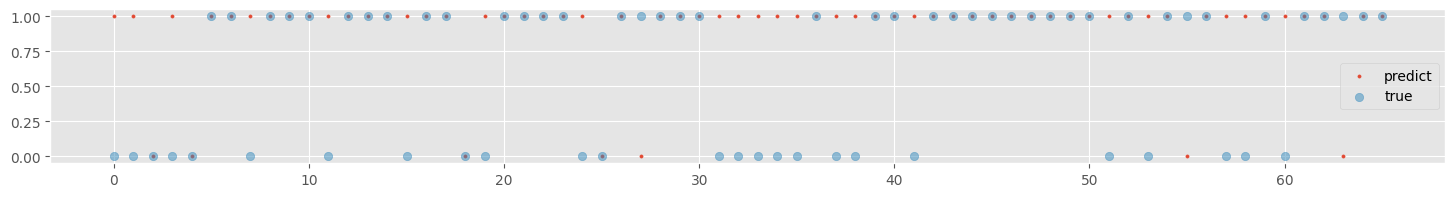

In [28]:
plt.figure(figsize=(18, 2))
plt.scatter(np.arange(66), y_pred, label='predict', s=5)
plt.scatter(np.arange(66), y_test, label='true', alpha=.5)
plt.legend()

Text(0.5, 1.0, 'Confusion Matrix for Logistic Regression')

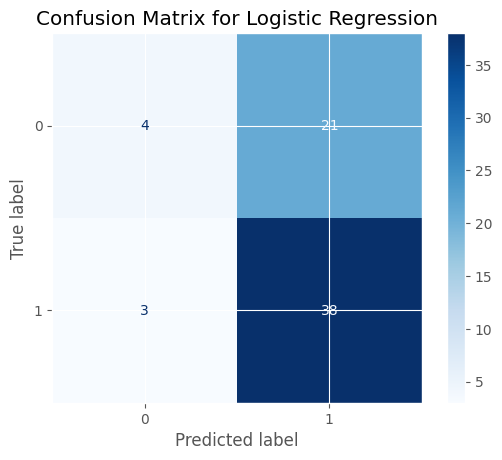

In [19]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix for Logistic Regression')


## Methods for selecting optimal algorithm parameters

Classification (regression) algorithms often depend on an input parameter p. How can the optimal value for p be found?

<br>

The simplest methods for parameter p selection:
1. Try as many different values of p as possible.
2. For each p, train a model and evaluate its quality.
3. Select the model and the value of p that yield the best performance.

>**Drawbacks**<br>The result depends on the particular train/test split.

## Cross-validation